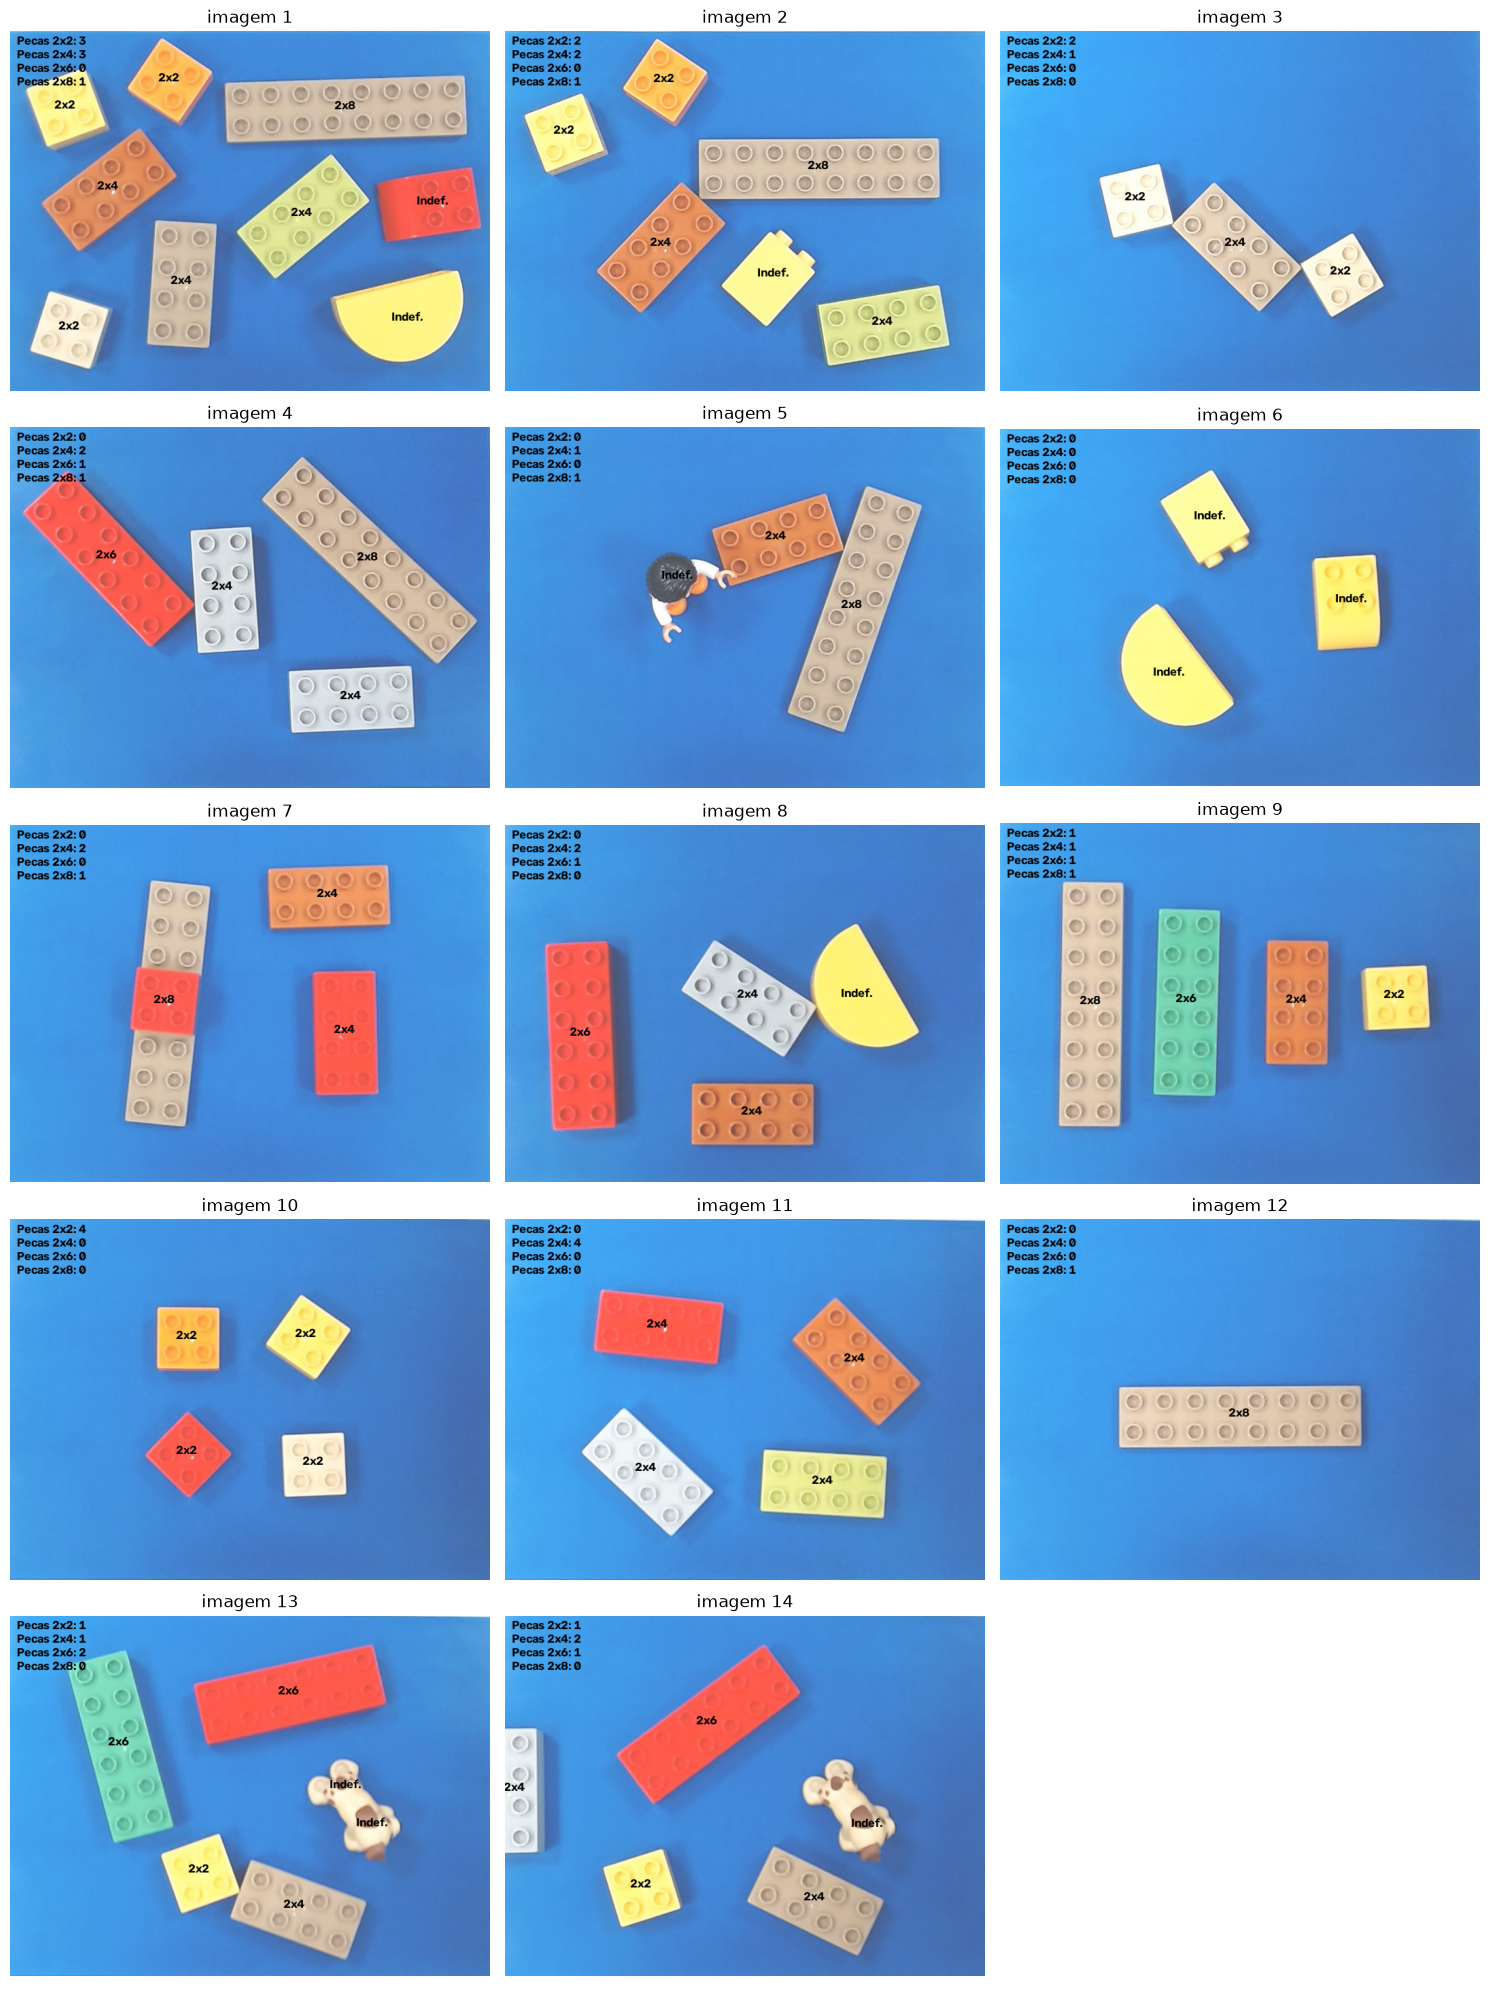

In [1]:
# ========= Imports =========
import cv2
import matplotlib.pyplot as plt
import numpy as np


# ========= Leitura das imagens =========
id = [1, 2, 4, 9, 10, 12, 11, 13,21, 22, 23, 25, 30, 32] # Mudar números caso necessário
imagens = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in id] # Mudar o nome do ficheiro


# ========= Funções =========

# Binarização
def pecas(img):

    cor = [] 

    for i in range(3):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        cor.append(np.argmax(hist))

    b, g, r = cor
    tol_b, tol_g, tol_r = 115, 73, 32 
    
    lim_inf = np.clip([b - tol_b, g - tol_g, r - tol_r], 0, 255)
    lim_sup = np.clip([b + tol_b, g + tol_g, r + tol_r], 0, 255)
    fundo = cv2.inRange(img, lim_inf, lim_sup)

    return 255 - fundo

# Operadores Morfológicos
kernel_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (14,14)) # abertura
kernel_f= cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)) # fecho
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15,15)) # erosão

def limpar(bin_):

    fecho = cv2.morphologyEx(bin_, cv2.MORPH_CLOSE, kernel_f)   
    abertura = cv2.morphologyEx(fecho, cv2.MORPH_OPEN, kernel_a)    

    return abertura

def separar(limpa, it=4):
    return cv2.erode(limpa, kernel, iterations=it)

# Extração de Características
margem = 4 * 7 * 2 

def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    area = cv2.contourArea(contorno) 
    ret = area / (w * h)
    w += margem
    h += margem
    maior, menor = max(w, h), min(w, h)

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret} 

# Classificação
def classificar(m):
    if m["retangularidade"] < 0.80:
        return None
    r = m["razao"]
    if 0.96 <= r <= 1.09: # + 0.04
        return "2x2"
    elif 1.84 <= r <= 2.14: # + 0.08
        return "2x4"
    elif 2.67 <= r <= 3.05: # + 0.12
        return "2x6"
    elif 3.49 <= r <= 4.14: # + 0.16
        return "2x8"
    return None


# Mostrar o resultados final
def contar(conts, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()

    for c in conts:
        m = medir(c)
        tipo = classificar(m)
        cx, cy = m["centro"]

        if tipo is None:
            cv2.putText(saida, "Indef.", (int(cx) - 17, int(cy)), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 
            continue

        contagem[tipo] += 1
        
        cv2.putText(saida, tipo, (int(cx) - 17, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 

    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return saida



# ========= Chamar funções =========

binarizacao = [pecas(img) for img in imagens]
img_limpo = [limpar(b) for b in binarizacao]
img_sep   = [separar(l) for l in img_limpo]
contornos = [cv2.findContours(ts, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] for ts in img_sep]
img_clasf = [contar(contornos[k], imagens[k]) for k in range(len(contornos))]


# ========= Print =========
colunas = 3
linhas = int(np.ceil(len(img_clasf) / colunas))

fig, ax = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
ax = ax.flatten()

index = 0
for k, img in enumerate(img_clasf):
    ax[k].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[k].set_title(f"imagem {index + 1}")
    ax[k].axis("off")
    index += 1

for k in range(len(img_clasf), len(ax)):
    ax[k].axis("off")

plt.tight_layout()
plt.show()